# Optimización de Retención y Valor de Clientes en un E-Commerce
## Caso de Estudio de Portafolio: Análisis Transaccional de Retail Minorista

### 1. Contexto del Negocio y Problemática
Una tienda de comercio electrónico internacional ha detectado que, a pesar de captar un volumen constante de nuevos usuarios, experimenta una alta tasa de abandono tras la primera compra. Adquirir un cliente nuevo en el ecosistema digital actual es sustancialmente más costoso que retener a uno existente. La dirección de marketing requiere un análisis de datos profundo para entender la dinámica de recompra y segmentar la base de datos de manera automatizada.

### 2. Objetivos del Proyecto
* **Cuantificar la deserción:** Medir la tasa de retención de clientes mediante un análisis de cohortes mensuales.
* **Segmentar la Base de Clientes:** Implementar un modelo de comportamiento RFM con base estadística (cuantiles).
* **Definir el Churn de Forma Predictiva:** Calcular el umbral de inactividad tolerada basándose en el ciclo natural de recompra del negocio.
* **Habilitar la Toma de Decisiones:** Exportar estructuras de datos optimizadas para su visualización interactiva en Tableau.


### 3. Limpieza de Datos e Ingeniería de Características
Para garantizar la fiabilidad del análisis, se aplican filtros estrictos de calidad de datos bajo criterios de negocio:
1. **Remoción de registros sin identificación (`CustomerID`):** Es imposible realizar análisis de retención o comportamiento sin un identificador único por cliente.
2. **Aislamiento de cancelaciones:** Las facturas que comienzan con la letra 'C' indican devoluciones o transacciones canceladas (cantidades negativas), las cuales se separan del flujo principal de ingresos netos.
3. **Corrección de anomalías de precio:** Se eliminan registros con precios unitarios o cantidades menores o iguales a cero (ajustes de inventario o pruebas de sistema).


In [2]:
# ==========================================
# FASE 1: ENTORNO, CARGA Y DESCOMPRESIÓN CORREGIDA
# ==========================================

import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

# Configuración estética global para reportes
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("🔄 Iniciando proceso de carga automatizado...")

# 1. Localizar de forma segura la carpeta de descargas del usuario en Windows
user_profile = os.environ['USERPROFILE']

# Intentaremos buscar el archivo bajo los dos nombres comunes para evitar errores
opciones_nombre = ['OnlineRetail.zip', 'OnlineRetall.zip']
zip_path = None

for nombre in opciones_nombre:
    ruta_prueba = os.path.join(user_profile, 'Downloads', nombre)
    if os.path.exists(ruta_prueba):
        zip_path = ruta_prueba
        break

# 2. Descomprimir si el archivo existe en descargas
if zip_path:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('data_retail')
    print(f"📦 Dataset localizado en '{zip_path}' y descomprimido con éxito en la carpeta local 'data_retail'.")
else:
    print("⚠️ No se encontró el archivo .zip en la carpeta de Descargas.")
    print("Asegúrate de que el archivo esté en Descargas o de haber creado manualmente la carpeta 'data_retail'.")

# 3. Carga con encoding específico para transacciones internacionales europeas
# Agregamos una verificación para guiarte en caso de que las rutas sigan movidas
ruta_csv = 'data_retail/OnlineRetail.csv'
if os.path.exists(ruta_csv):
    df = pd.read_csv(ruta_csv, encoding='ISO-8859-1')
    print(f"✅ Dataset cargado correctamente. Registros iniciales en memoria: {df.shape[0]:,}")
else:
    raise FileNotFoundError(f"❌ Error crítico: No se encontró el archivo '{ruta_csv}'. Verifica que el archivo ZIP esté descargado.")


🔄 Iniciando proceso de carga automatizado...
📦 Dataset localizado en 'C:\Users\Ainara Ximena\Downloads\OnlineRetail.zip' y descomprimido con éxito en la carpeta local 'data_retail'.
✅ Dataset cargado correctamente. Registros iniciales en memoria: 541,909


In [3]:
# ==========================================
# FASE 2: CLEANING PIPELINE Y FEATURE ENGINEERING
# ==========================================

# 1. Limpieza transaccional estricta
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['TotalRevenue'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['IsCancellation'] = df_clean['InvoiceNo'].str.startswith('C', na=False)

# 2. Dataset exclusivo de compras exitosas (Ventas Netas)
df_sales = df_clean[(df_clean['IsCancellation'] == False) & 
                    (df_clean['Quantity'] > 0) & 
                    (df_clean['UnitPrice'] > 0)].copy()

# 3. Transformación transaccional -> Agregación a nivel de cliente único
snapshot_date = df_sales['InvoiceDate'].max() + dt.timedelta(days=1)

customer_df = df_sales.groupby('CustomerID').agg({
    'InvoiceDate': [
        lambda x: (snapshot_date - x.max()).days,  # Recencia (Días de inactividad)
        lambda x: (snapshot_date - x.min()).days,  # Antigüedad (Tenure)
        'nunique'                                  # Frecuencia (Órdenes únicas)
    ],
    'TotalRevenue': 'sum',                         # Valor Monetario (Inversión acumulada)
    'InvoiceNo': 'count'                           # Volumen de artículos comprados
}).reset_index()

# Renombrar columnas para mantener consistencia profesional
customer_df.columns = ['CustomerID', 'Recency', 'Tenure', 'Frequency', 'MonetaryValue', 'TotalItemsBought']

# Calcular indicadores complementarios de negocio
customer_df['AvgTicket'] = customer_df['MonetaryValue'] / customer_df['Frequency']
customer_df['CustomerType'] = np.where(customer_df['Frequency'] > 1, 'Recurrente', 'Una Sola Comra')

print(f"🎉 Pipeline completado. Base de datos depurada con {customer_df['CustomerID'].nunique():,} clientes únicos.")


🎉 Pipeline completado. Base de datos depurada con 4,338 clientes únicos.


### 4. Análisis de Cohortes Mensuales (Mapeo de Retención)
Se agrupa a los clientes en "cohortes" basadas en el mes de su primera transacción comercial. El `CohortIndex` representa el mes calendario de vida del cliente. Esto nos permite rastrear con precisión milimétrica la velocidad de abandono del e-commerce.


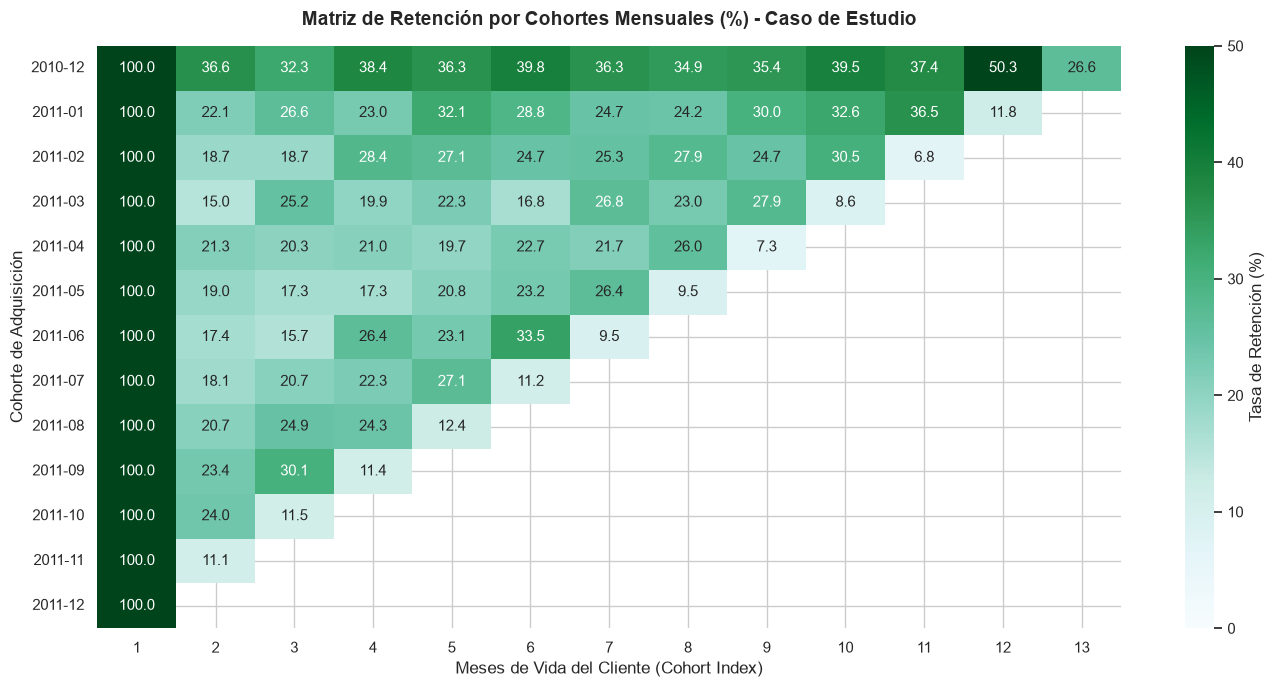

In [4]:
# ==========================================
# FASE 3: MODELADO DE COHORTES MENSUALES
# ==========================================

# Truncar fechas al primer día del mes para agrupación temporal
df_sales['InvoiceMonth'] = df_sales['InvoiceDate'].apply(lambda x: dt.datetime(x.year, x.month, 1))
df_sales['CohortMonth'] = df_sales.groupby('CustomerID')['InvoiceMonth'].transform('min')

# Calcular desfase en meses de vida activa
invoice_year, invoice_month = df_sales['InvoiceMonth'].dt.year, df_sales['InvoiceMonth'].dt.month
cohort_year, cohort_month = df_sales['CohortMonth'].dt.year, df_sales['CohortMonth'].dt.month

years_diff = invoice_year - cohort_year
months_diff = invoice_month - cohort_month
df_sales['CohortIndex'] = years_diff * 12 + months_diff + 1

# Estructurar matriz de recuento absoluto
cohort_data = df_sales.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()
cohort_matrix = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

# Convertir matriz a porcentajes relativos de retención
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0) * 100
retention_matrix.index = retention_matrix.index.strftime('%Y-%m')

# Desplegar visualización analítica de calor (Heatmap)
plt.figure(figsize=(14, 7))
plt.title('Matriz de Retención por Cohortes Mensuales (%) - Caso de Estudio', fontsize=14, fontweight='bold', pad=15)
sns.heatmap(data=retention_matrix, annot=True, fmt='.1f', vmin=0, vmax=50, cmap='BuGn', cbar_kws={'label': 'Tasa de Retención (%)'})
plt.ylabel('Cohorte de Adquisición')
plt.xlabel('Meses de Vida del Cliente (Cohort Index)')
plt.tight_layout()
plt.show()


### 5. Segmentación RFM de Base Estadística
Clasificamos a los consumidores utilizando quintiles (5 grupos idénticos de 20% de la población cada uno). Sumar estos scores individuales genera una métrica unificada de valor (`RFM_Score`) que mapea a los clientes en etiquetas de negocio estratégicas de cara al diseño de campañas de marketing dirigidas.


In [5]:
# ==========================================
# FASE 4: MODELADO Y SEGMENTACIÓN RFM
# ==========================================

# 1. Asignación estadística de puntajes mediante cuantiles
customer_df['R_Score'] = pd.qcut(customer_df['Recency'], q=5, labels=range(5, 0, -1))
customer_df['F_Score'] = pd.qcut(customer_df['Frequency'].rank(method='first'), q=5, labels=range(1, 6))
customer_df['M_Score'] = pd.qcut(customer_df['MonetaryValue'], q=5, labels=range(1, 6))

customer_df['RFM_Segment'] = customer_df['R_Score'].astype(str) + customer_df['F_Score'].astype(str) + customer_df['M_Score'].astype(str)
customer_df['RFM_Score'] = customer_df[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

# 2. Definición lúdica de perfiles estratégicos de cliente
def segmentar_clientes(df):
    if df['RFM_Score'] >= 14: return 'Campeones (VIP)'
    elif df['RFM_Score'] >= 11: return 'Clientes Leales'
    elif (df['R_Score'] >= 3) & (df['F_Score'] >= 3): return 'Clientes Prometedores'
    elif (df['R_Score'] <= 2) & (df['F_Score'] >= 3): return 'En Riesgo Alto'
    elif (df['R_Score'] <= 2) & (df['F_Score'] <= 2): return 'Perdidos e Inactivos'
    else: return 'Necesitan Atención'

customer_df['Segmento_Negocio'] = customer_df.apply(segmentar_clientes, axis=1)

# 3. Generación del reporte financiero ejecutivo
resumen_rfm = customer_df.groupby('Segmento_Negocio').agg({
    'CustomerID': 'count',
    'MonetaryValue': 'sum',
    'Recency': 'mean',
    'Frequency': 'mean'
}).rename(columns={'CustomerID': 'Cantidad_Clientes', 'MonetaryValue': 'Ingreso_Total'}).reset_index()

resumen_rfm['%_Clientes'] = (resumen_rfm['Cantidad_Clientes'] / resumen_rfm['Cantidad_Clientes'].sum()) * 100
resumen_rfm['%_Ingresos'] = (resumen_rfm['Ingreso_Total'] / resumen_rfm['Ingreso_Total'].sum()) * 100

print("🎯 Segmentación completada. Reporte ejecutivo por volumen de facturación:")
display(resumen_rfm.sort_values(by='Ingreso_Total', ascending=False).reset_index(drop=True))


🎯 Segmentación completada. Reporte ejecutivo por volumen de facturación:


,Segmento_Negocio,Cantidad_Clientes,Ingreso_Total,Recency,Frequency,%_Clientes,%_Ingresos
0,Campeones (VIP),649,5272208.370,10.362096,13.918336,14.960811,59.162463
1,Clientes Leales,951,2033204.051,33.505783,4.936909,21.922545,22.815744
2,En Riesgo Alto,567,556987.671,158.167549,2.874780,13.070539,6.250277
3,Perdidos e Inactivos,1063,518661.552,217.952963,1.099718,24.504380,5.820198
4,Necesitan Atención,656,278393.550,37.512195,1.184451,15.122176,3.124013
5,Clientes Prometedores,452,251952.710,37.303097,2.513274,10.419548,2.827305


### 6. Análisis Predictivo de Churn Basado en la Distribución de Recompra
Para calcular de forma rigurosa la deserción sin recurrir a suposiciones arbitrarias, analizamos el intervalo de días transcurridos entre transacciones de los compradores recurrentes. Fijar el umbral en el **Percentil 80** indica que si un cliente excede este número de días inactivo, ha roto su patrón comercial típico, teniendo un 80% de probabilidad de haber abandonado el e-commerce.


📐 Calculando métrica real de tiempo transcurrido entre visitas...

📊 --- DIAGNÓSTICO ESTADÍSTICO DE RECOMPRA ---
• Mediana del tiempo entre compras: 52.0 días.
• Umbral Crítico de Churn (Percentil 80): 112.0 días.
• Tasa de Abandono Global Calculada (Churn Rate): 29.46%


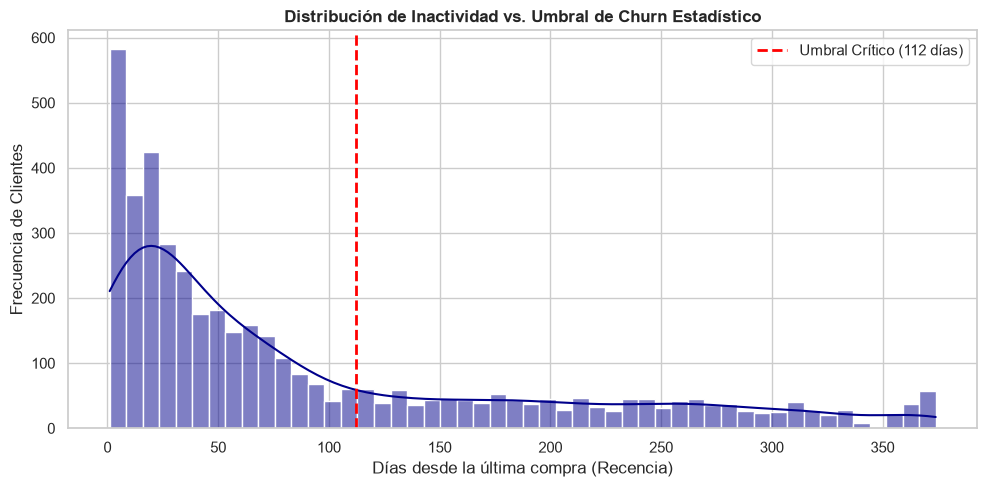


💾 ¡Ficheros optimizados generados con éxito en la raíz del proyecto para conectar a Tableau!


In [6]:
# ==========================================
# FASE 5: MODELADO ESTADÍSTICO DE CHURN Y EXPORTACIÓN
# ==========================================

print("📐 Calculando métrica real de tiempo transcurrido entre visitas...")

# 1. Aislar visitas únicas a nivel de orden para evitar el sesgo de múltiples artículos
ordenes_unicas = df_sales[['CustomerID', 'InvoiceNo', 'InvoiceDate']].drop_duplicates()
ordenes_unicas = ordenes_unicas.sort_values(by=['CustomerID', 'InvoiceDate'])

# 2. Desplazar renglones temporales (Shift) por consumidor
ordenes_unicas['PrevInvoiceDate'] = ordenes_unicas.groupby('CustomerID')['InvoiceDate'].shift(1)
ordenes_unicas['DaysBetween'] = (ordenes_unicas['InvoiceDate'] - ordenes_unicas['PrevInvoiceDate']).dt.days

# 3. Extraer la mediana de recompra por cliente recurrente
intervalos_reales = ordenes_unicas[ordenes_unicas['DaysBetween'] > 0]
customer_time_clean = intervalos_reales.groupby('CustomerID')['DaysBetween'].median().reset_index()

# 4. Cálculo de parámetros estadísticos descriptivos
mediana_recompra_real = customer_time_clean['DaysBetween'].median()
umbral_churn_real = customer_time_clean['DaysBetween'].quantile(0.80)

print(f"\n📊 --- DIAGNÓSTICO ESTADÍSTICO DE RECOMPRA ---")
print(f"• Mediana del tiempo entre compras: {mediana_recompra_real:.1f} días.")
print(f"• Umbral Crítico de Churn (Percentil 80): {umbral_churn_real:.1f} días.")

# 5. Etiquetado binario predictivo (0 = Activo, 1 = Churn)
customer_df['Is_Churn'] = np.where(customer_df['Recency'] > umbral_churn_real, 1, 0)
print(f"• Tasa de Abandono Global Calculada (Churn Rate): {customer_df['Is_Churn'].mean() * 100:.2f}%")

# 6. Despliegue visual del histograma analítico
plt.figure(figsize=(10, 5))
sns.histplot(customer_df['Recency'], bins=50, kde=True, color='darkblue')
plt.axvline(umbral_churn_real, color='red', linestyle='--', linewidth=2, label=f'Umbral Crítico ({int(umbral_churn_real)} días)')
plt.title('Distribución de Inactividad vs. Umbral de Churn Estadístico', fontsize=12, fontweight='bold')
plt.xlabel('Días desde la última compra (Recencia)')
plt.ylabel('Frecuencia de Clientes')
plt.legend()
plt.tight_layout()
plt.show()

# 7. EXPORTACIÓN DE DATASETS COMPLEMENTARIOS PARA TABLEAU
# Archivo transaccional limpio para series de tiempo, mapas y análisis de SKUs
df_sales.to_csv('online_retail_transactions_clean.csv', index=False)

# Archivo de comportamiento maestro por cliente con variables RFM y Churn
customer_df.to_csv('online_retail_customer_summary.csv', index=False)

print("\n💾 ¡Ficheros optimizados generados con éxito en la raíz del proyecto para conectar a Tableau!")
